In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')
from scipy.interpolate import griddata

In [ ]:
X = np.load('..\Function_2_Data\Week_6_Data/F2_Week_6_inputs.npy')
Y = np.load('..\Function_2_Data\Week_6_Data/F2_Week_6_outputs.npy')

((15, 2),
 array([ 0.53899612,  0.42058624, -0.06562362,  0.29399291,  0.21496451,
         0.02310555,  0.24461934,  0.03874902, -0.01385762,  0.61120522,
         0.07751897,  0.61355204,  0.60507048,  0.54255166,  0.48391765]))

In [3]:
Y_max=Y[0:-1].max()
Y_max_new=Y.max()
Y_max_new - Y_max, Y_max, Y_max_new

(np.float64(0.0),
 np.float64(0.6135520414429663),
 np.float64(0.6135520414429663))

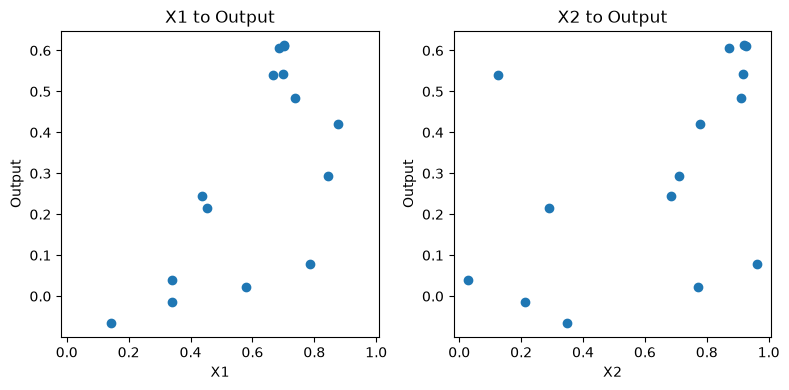

In [4]:
# Create 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True)

# Scatterplot of first array
axes[0].scatter(X[:,0], Y)
axes[0].set_title('X1 to Output')
axes[0].set_xlabel('X1')
axes[0].set_ylabel('Output')

# Scatterplot of second array
axes[1].scatter(X[:,1], Y)
axes[1].set_title('X2 to Output')
axes[1].set_xlabel('X2')
axes[1].set_ylabel('Output')

plt.tight_layout()
plt.show()
# New query: 0.711613-0.920992 - lcb - kappa = 1.0 - Isotropic Mattern2.5 - 19.08.26
# New query: 0.737489-0.910018 - ei  - xi = 0.1    - Isotropic Mattern2.5 - 19.08.26

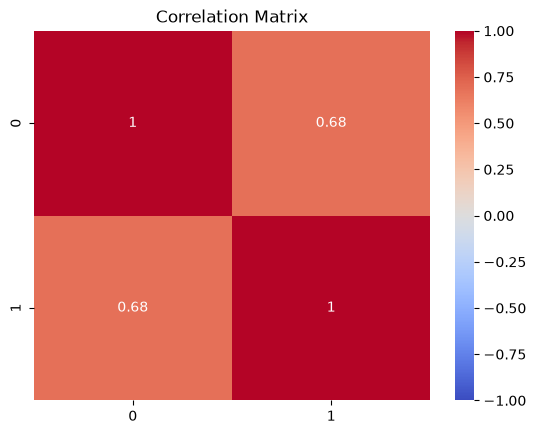

In [7]:
import seaborn as sns
import pandas as pd
df=pd.DataFrame(data=X)
corr = df.corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)

plt.title("Correlation Matrix")
plt.show()

In [8]:
kernel = Matern(length_scale=0.1, nu=2.5)
# kernel = Matern(length_scale=[0.5, 0.5], nu=2.5)
# kernel = ConstantKernel(1.0) * RBF(length_scale=[1.0, 1.0])
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10)
gp.fit(X, Y)

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.","Matern(length...e=0.1, nu=2.5)"
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-06
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",10
,kernel__length_scale,0.1
,kernel__length_scale_bounds,"(1e-05, ...)"
,kernel__nu,2.5
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False
,"copy_X_train copy_X_train: bool, default=TrueIf True, a persistent copy of the training data is stored in theobject. Otherwise, just a reference to the training data is stored,which might cause predictions to change if the data is modifiedexternally.",True
,"n_targets n_targets: int, default=NoneThe number of dimensions of the target values. Used to decide the numberof outputs when sampling from the prior distributions (i.e. calling:meth:`sample_y` before :meth:`fit`). This parameter is ignored once:meth:`fit` has been called... versionadded:: 1.3",None
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation used to initialize the centers.Pass an int for 

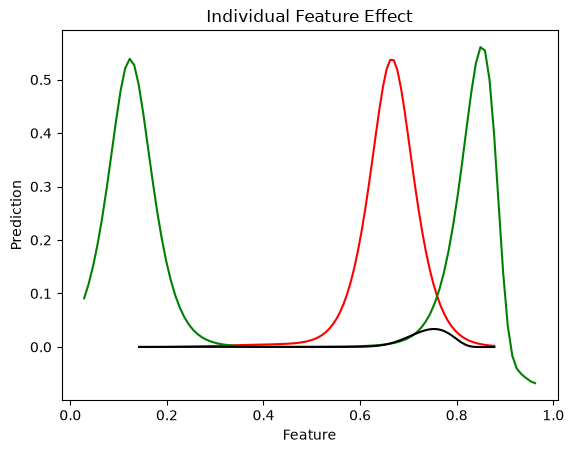

In [9]:
sample = X[0].copy()
feature0 = 0
feature1 = 1
values0 = np.linspace(X[:, feature0].min(), X[:, feature0].max(), 100)
values1 = np.linspace(X[:, feature1].min(), X[:, feature1].max(), 100)
predictions0 = []
predictions1 = []
for v in values0:
    temp = sample.copy()
    temp[feature0] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions0.append(pred)
for v in values1:
    temp = sample.copy()
    temp[feature1] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions1.append(pred)
Pred0_plus_Pred1 = [x * y for x, y in zip(predictions0, predictions1)]
plt.plot(values0, predictions0, color = 'red', label = 'Feature 1')
plt.plot(values1, predictions1, color = 'green', label = 'Feature 2')
plt.plot(values0, Pred0_plus_Pred1, color = 'black', label = 'F1*F2')
plt.xlabel("Feature")
plt.ylabel("Prediction")
plt.title("Individual Feature Effect")
plt.show()

In [11]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    UCB = mean + kappa * std
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma

def lower_confidence_bound(mu, sigma, kappa=2.0):
    """
    Lower Confidence Bound (UCB) acquisition function.
    LCB = mean - kappa * std
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu - kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    EI = E[max(f(x) - f(x_best), 0)]
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [12]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    elif acquisition == 'lcb':
        acq_val = lower_confidence_bound(mu, sigma, kappa=1.25)
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=2.5)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [14]:
acquisition='lcb'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

for _ in range(30):  # Multiple random starts
    x0 = np.random.uniform([b[0] for b in bounds], [b[1] for b in bounds])
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

np.set_printoptions(suppress=True, precision=6)
print(f'New query: {X_next[0]:.6f}-{X_next[1]:.6f}')  
# New query: 0.702119-0.919585
# New query: 0.701697-0.914040
# New query: 0.687473-0.871597 - lcb - kappa = 0.05 - 05.08.26
# New query: 0.697056-0.200216 - lcb - kappa = 0.05 - 12.08.26
# New query: 0.701366-0.000000 - ei - xi = 0.05 - 12.08.26
# New query: 0.699032-0.909008  - lcb - kappa = 2.5 - 12.08.26
# New query: 0.701245-0.919298  - lcb - kappa = 2.5 - Anisotropic Mattern2.5 - 13.08.26
# New query: 0.700120-0.915531  - lcb - kappa = 2.5 - Isotropic Mattern2.5 - 13.08.26
# New query: 1.000000-0.000000 - ei - xi = 0.1 - Anisotropic Mattern2.5 - 13.08.26
# New query: 0.505378-1.000000 - ei - xi = 0.1 - Isotropic Mattern2.5 - 13.08.26

# New query: 0.711613-0.920992 - lcb - kappa = 1.0 - Isotropic Mattern2.5 - 19.08.26
# New query: 0.737489-0.910018 - ei  - xi = 0.1    - Isotropic Mattern2.5 - 19.08.26

# New query: 0.705064-0.922042 - lcb - kappa = 1.25 - Isotropic Mattern2.5 - 27.08.26
# New query: 0.693717-0.823458 - ei  - xi = 0.01    - Isotropic Mattern2.5 - 27.08.26

New query: 0.705064-0.922042


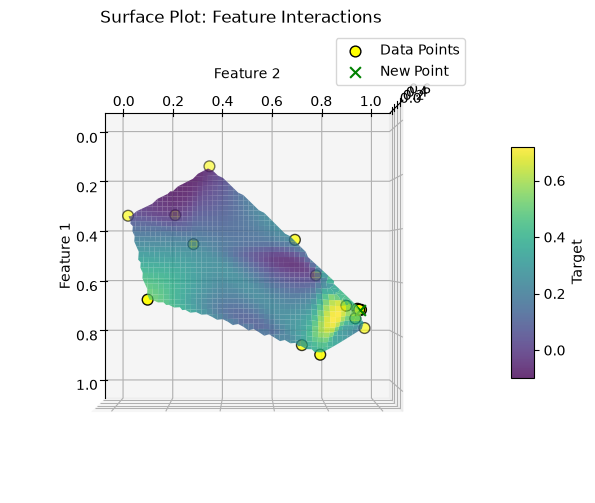

In [15]:
# **3D Surface Plot (Separate Block for Feature Interaction)**

x1, x2 = X[:, 0], X[:, 1]
z = Y

# Create grid points for interpolation
grid_x1, grid_x2 = np.meshgrid(
    np.linspace(0, 1, 100),
    np.linspace(0, 1, 100)
)

# Interpolate the Z values for the grid
grid_z = griddata(
    (x1, x2), z, 
    (grid_x1, grid_x2), 
    method="cubic"
)

# Plotting the surface
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(
    grid_x1, grid_x2, grid_z, 
    cmap="viridis", 
    edgecolor="none", 
    alpha=0.8
)
# Scatter points (data points)
ax.scatter(x1, x2, z, color='yellow', edgecolor='black', s=60, label="Data Points")
#ax.scatter(X_next[0], X_next[1], 0.6, marker='x', color='green', edgecolor='black', s=60, label="New Point")
ax.scatter(X_next[0], X_next[1], Y.max(), marker='x', color='green', edgecolor='black', s=60, label="New Point")
ax.legend(loc="best")  # Add legend for clarity
ax.view_init(elev=90, azim=0)

cb = fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
cb.set_label("Target")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")

plt.title("Surface Plot: Feature Interactions")
plt.show()
